<a href="https://colab.research.google.com/github/UlyaBatool/Data_and_sciences/blob/main/California_Housing_ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Checking whether python code is exceuting or not
print("Hello world!")

Hello world!


In [ ]:
import sys

print("Python version:", sys.version)

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("All required libraries imported successfully!")

NumPy: 2.1.3
Pandas: 2.2.3
SciPy: 1.16.3
Scikit-learn: 1.6.1
All required libraries imported successfully!


In [ ]:
import os
import tarfile
from six.moves import urllib

DOWNLOAD_ROOT = "https://raw.githubusercontent.com/ageron/handson-ml2/master/"
HOUSING_PATH = "datasets/housing"
HOUSING_URL = DOWNLOAD_ROOT + "datasets/housing/housing.tgz"

def fetch_housing_data(
    housing_url=HOUSING_URL,
    housing_path=HOUSING_PATH
):
    os.makedirs(housing_path, exist_ok=True)

    tgz_path = os.path.join(housing_path, "housing.tgz")
    urllib.request.urlretrieve(housing_url, tgz_path)

    with tarfile.open(tgz_path) as housing_tgz:
        housing_tgz.extractall(
            path=housing_path,
            filter="data"
        )

fetch_housing_data()

print("Dataset files:", os.listdir(HOUSING_PATH))

Dataset files: ['housing.tgz', 'housing.csv']


In [ ]:
def load_housing_data(housing_path=HOUSING_PATH):
    csv_path = os.path.join(housing_path, "housing.csv")
    return pd.read_csv(csv_path)

housing = load_housing_data()

print("Dataset loaded successfully!")
print("Number of rows:", len(housing))
print("Number of columns:", len(housing.columns))

Dataset loaded successfully!
Number of rows: 20640
Number of columns: 10


In [ ]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [ ]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [ ]:
housing["ocean_proximity"].value_counts()

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


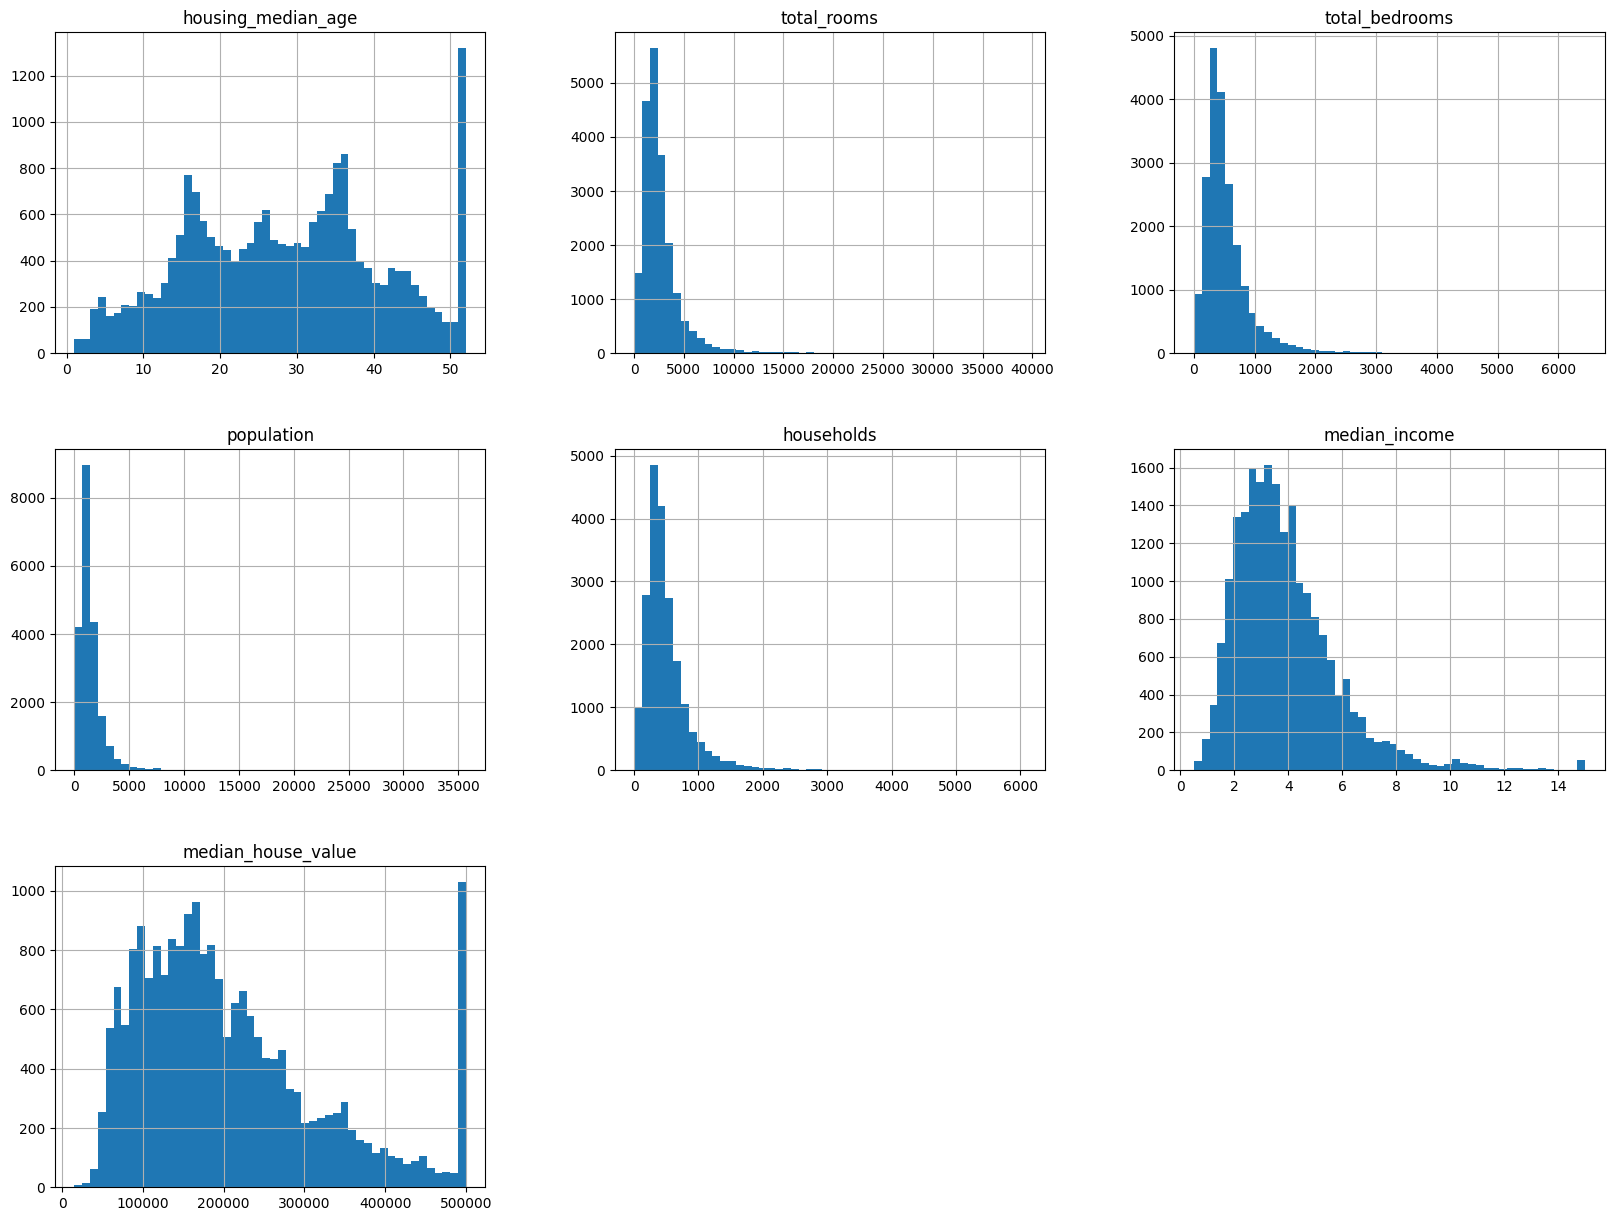

In [ ]:
import matplotlib.pyplot as plt

housing.drop(columns=["longitude", "latitude"]).hist(
    bins=50,
    figsize=(20, 15)
)

plt.show()

In [ ]:
import numpy as np

def split_train_test(data, test_ratio):
    shuffled_indices = np.random.permutation(len(data))
    test_set_size = int(len(data) * test_ratio)

    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]

    return data.iloc[train_indices], data.iloc[test_indices]

np.random.seed(42)

train_set, test_set = split_train_test(housing, 0.2)

print("Training set size:", len(train_set))
print("Test set size:", len(test_set))

Training set size: 16512
Test set size: 4128


In [ ]:
housing["income_cat"] = pd.cut(
    housing["median_income"],
    bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
    labels=[1, 2, 3, 4, 5]
)

housing["income_cat"].value_counts().sort_index()

,count
income_cat,
1,822
2,6581
3,7236
4,3639
5,2362


In [ ]:
from sklearn.model_selection import StratifiedShuffleSplit

split = StratifiedShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

for train_index, test_index in split.split(
    housing, housing["income_cat"]
):
    strat_train_set = housing.loc[train_index].copy()
    strat_test_set = housing.loc[test_index].copy()

print("Training set size:", len(strat_train_set))
print("Test set size:", len(strat_test_set))

Training set size: 16512
Test set size: 4128


In [ ]:
print("Overall income proportions:")
print(
    housing["income_cat"].value_counts(normalize=True).sort_index()
)

print("\nTraining-set income proportions:")
print(
    strat_train_set["income_cat"].value_counts(normalize=True).sort_index()
)

print("\nTest-set income proportions:")
print(
    strat_test_set["income_cat"].value_counts(normalize=True).sort_index()
)

Overall income proportions:
income_cat
1    0.039826
2    0.318847
3    0.350581
4    0.176308
5    0.114438
Name: proportion, dtype: float64

Training-set income proportions:
income_cat
1    0.039789
2    0.318859
3    0.350594
4    0.176296
5    0.114462
Name: proportion, dtype: float64

Test-set income proportions:
income_cat
1    0.039971
2    0.318798
3    0.350533
4    0.176357
5    0.114341
Name: proportion, dtype: float64


In [ ]:
for set_ in (strat_train_set, strat_test_set):
    set_.drop("income_cat", axis=1, inplace=True)

print("Training columns:", strat_train_set.columns.tolist())
print("Test columns:", strat_test_set.columns.tolist())

Training columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']
Test columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']


In [ ]:
housing = strat_train_set.copy()

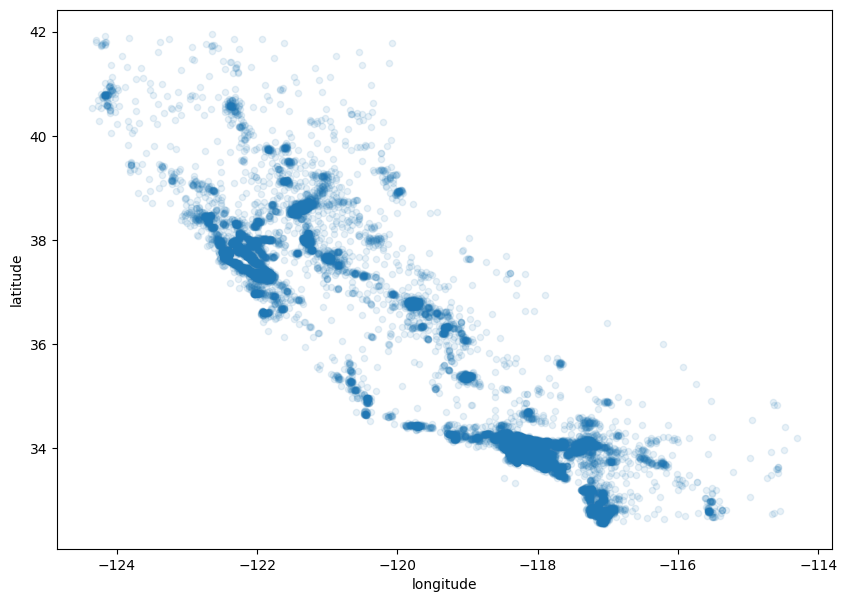

In [ ]:
housing.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    alpha=0.1,
    figsize=(10, 7)
)

plt.show()

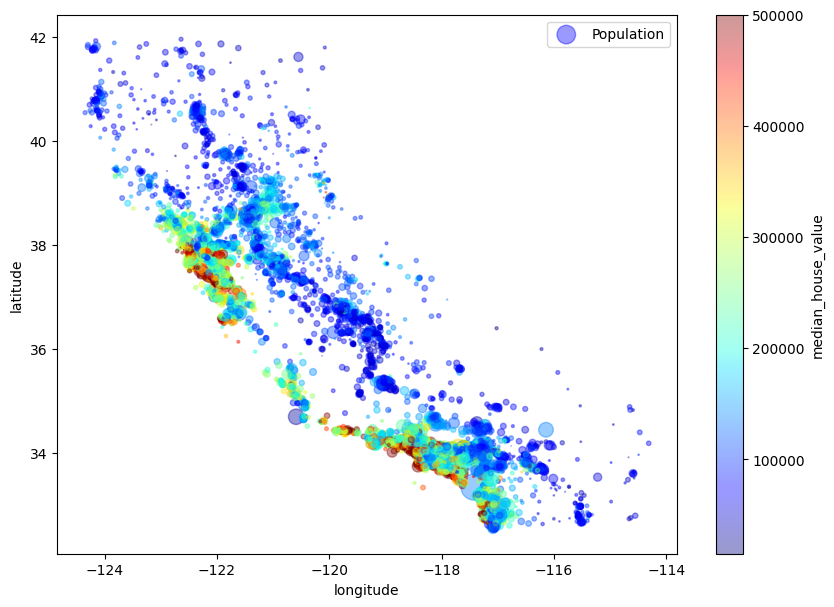

In [ ]:
housing.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    alpha=0.4,
    s=housing["population"] / 100,
    label="Population",
    figsize=(10, 7),
    c="median_house_value",
    cmap=plt.get_cmap("jet"),
    colorbar=True,
    sharex=False
)

plt.legend()
plt.show()

In [ ]:
corr_matrix = housing.corr(numeric_only=True)

corr_matrix["median_house_value"].sort_values(
    ascending=False
)

,median_house_value
median_house_value,1.000000
median_income,0.687151
total_rooms,0.135140
housing_median_age,0.114146
households,0.064590
total_bedrooms,0.047781
population,-0.026882
longitude,-0.047466
latitude,-0.142673


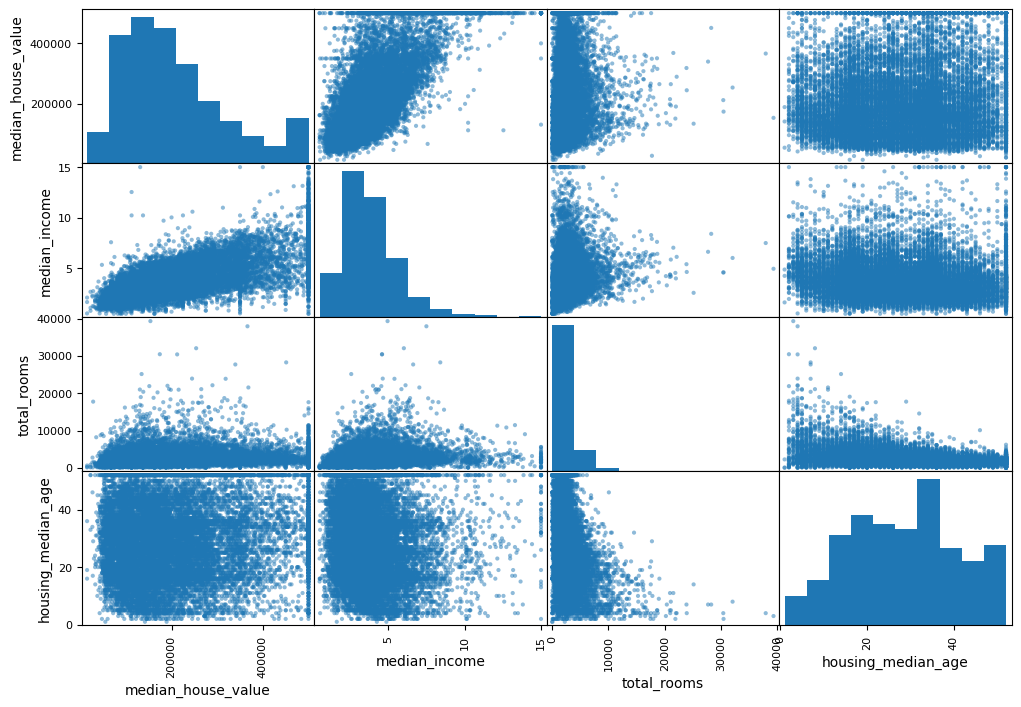

In [ ]:
from pandas.plotting import scatter_matrix

attributes = [
    "median_house_value",
    "median_income",
    "total_rooms",
    "housing_median_age"
]

scatter_matrix(
    housing[attributes],
    figsize=(12, 8)
)

plt.show()

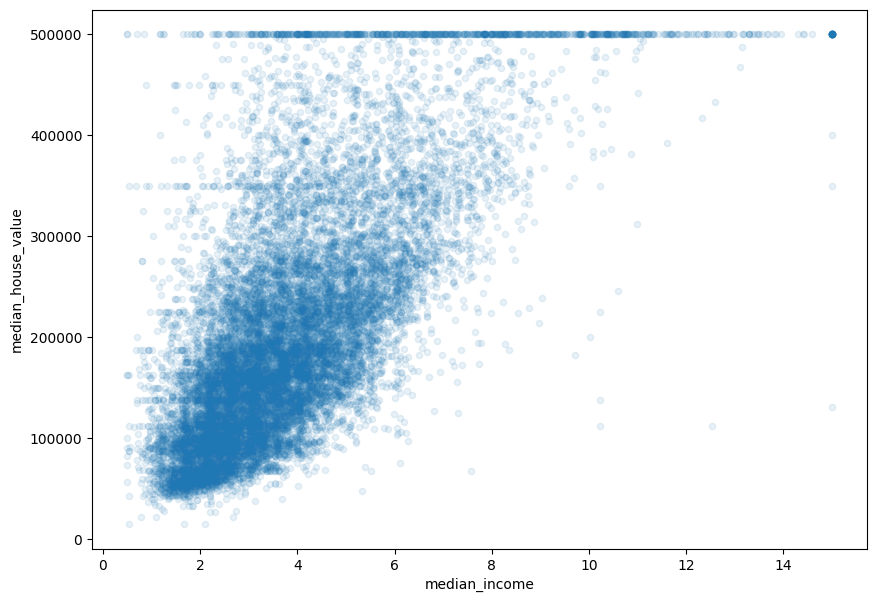

In [ ]:
housing.plot(
    kind="scatter",
    x="median_income",
    y="median_house_value",
    alpha=0.1,
    figsize=(10, 7)
)

plt.show()

In [ ]:
housing = strat_train_set.drop(
    "median_house_value",
    axis=1
)

housing_labels = strat_train_set["median_house_value"].copy()

print("Features shape:", housing.shape)
print("Labels shape:", housing_labels.shape)

Features shape: (16512, 9)
Labels shape: (16512,)


In [ ]:
housing.isnull().sum()
print("Total missing values:", housing.isnull().sum().sum())

Total missing values: 158


In [ ]:
median_bedrooms = housing["total_bedrooms"].median()

housing["total_bedrooms"] = housing["total_bedrooms"].fillna(
    median_bedrooms
)

print("Median total bedrooms:", median_bedrooms)
print("Remaining missing values:", housing.isnull().sum().sum())

Median total bedrooms: 433.0
Remaining missing values: 0


In [ ]:
housing_cat = housing[["ocean_proximity"]]

print(housing_cat.head(10))

      ocean_proximity
12655          INLAND
15502      NEAR OCEAN
2908           INLAND
14053      NEAR OCEAN
20496       <1H OCEAN
1481         NEAR BAY
18125       <1H OCEAN
5830        <1H OCEAN
17989       <1H OCEAN
4861        <1H OCEAN


In [ ]:
from sklearn.preprocessing import OrdinalEncoder

ordinal_encoder = OrdinalEncoder()

housing_cat_encoded = ordinal_encoder.fit_transform(housing_cat)

print(housing_cat_encoded[:10])
print("Categories:", ordinal_encoder.categories_)

[[1.]
 [4.]
 [1.]
 [4.]
 [0.]
 [3.]
 [0.]
 [0.]
 [0.]
 [0.]]
Categories: [array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]


In [ ]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder()

housing_cat_1hot = cat_encoder.fit_transform(housing_cat)

print(housing_cat_1hot.toarray()[:10])
print("Categories:", cat_encoder.categories_)

[[0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]]
Categories: [array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("std_scaler", StandardScaler()),
])

print("Numerical preprocessing pipeline created successfully!")

Numerical preprocessing pipeline created successfully!


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

housing_num = strat_train_set.drop(
    ["median_house_value", "ocean_proximity"], axis=1
)

num_attribs = list(housing_num.columns)
cat_attribs = ["ocean_proximity"]

print("Numerical features:", num_attribs)
print("Number of numerical features:", len(num_attribs))
print("Categorical features:", cat_attribs)

Numerical features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Number of numerical features: 8
Categorical features: ['ocean_proximity']


In [ ]:
full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("cat", OneHotEncoder(), cat_attribs),
])

print("Complete preprocessing pipeline created successfully!")

Complete preprocessing pipeline created successfully!


In [ ]:
housing_prepared = full_pipeline.fit_transform(
    strat_train_set.drop("median_house_value", axis=1)
)

print("Prepared dataset shape:", housing_prepared.shape)
print("Expected rows:", len(strat_train_set))
print("Missing values before preprocessing:",
      strat_train_set.drop("median_house_value", axis=1).isnull().sum().sum())

Prepared dataset shape: (16512, 13)
Expected rows: 16512
Missing values before preprocessing: 158


In [ ]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(housing_prepared, housing_labels)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [ ]:
housing_predictions = lin_reg.predict(housing_prepared)

print("First 5 predictions:", housing_predictions[:5])
print("First 5 actual values:", housing_labels.iloc[:5].values)

First 5 predictions: [ 88983.14806384 305351.35385026 153334.71183453 184302.55162102
 246840.18988841]
First 5 actual values: [ 72100. 279600.  82700. 112500. 238300.]


In [ ]:
from sklearn.metrics import mean_squared_error
import numpy as np

lin_mse = mean_squared_error(
    housing_labels,
    housing_predictions
)

lin_rmse = np.sqrt(lin_mse)

print("Linear Regression MSE:", lin_mse)
print("Linear Regression RMSE:", lin_rmse)

Linear Regression MSE: 4767980139.451871
Linear Regression RMSE: 69050.56219504567


In [ ]:
from sklearn.model_selection import cross_val_score

lin_scores = cross_val_score(
    lin_reg,
    housing_prepared,
    housing_labels,
    scoring="neg_mean_squared_error",
    cv=10
)

lin_rmse_scores = np.sqrt(-lin_scores)

print("RMSE scores for each fold:")
print(lin_rmse_scores)

print("\nMean RMSE:", lin_rmse_scores.mean())
print("Standard deviation:", lin_rmse_scores.std())

RMSE scores for each fold:
[72229.03469752 65318.2240289  67706.39604745 69368.53738998
 66767.61061621 73003.75273869 70522.24414582 69440.77896541
 66930.32945876 70756.31946074]

Mean RMSE: 69204.32275494763
Standard deviation: 2372.070791055922


In [ ]:
from sklearn.tree import DecisionTreeRegressor

tree_reg = DecisionTreeRegressor(random_state=42)

tree_reg.fit(housing_prepared, housing_labels)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [ ]:
tree_scores = cross_val_score(
    tree_reg,
    housing_prepared,
    housing_labels,
    scoring="neg_mean_squared_error",
    cv=10
)

tree_rmse_scores = np.sqrt(-tree_scores)

print("Decision Tree RMSE scores for each fold:")
print(tree_rmse_scores)

print("\nMean RMSE:", tree_rmse_scores.mean())
print("Standard deviation:", tree_rmse_scores.std())

Decision Tree RMSE scores for each fold:
[71177.6601991  69770.07865373 64770.5639395  68536.60203993
 67057.08155801 68847.12456973 70977.38255647 69208.86346929
 67187.87131535 73280.38732407]

Mean RMSE: 69081.361562518
Standard deviation: 2296.288087393378


In [ ]:
tree_predictions = tree_reg.predict(housing_prepared)

tree_mse = mean_squared_error(
    housing_labels,
    tree_predictions
)

tree_rmse = np.sqrt(tree_mse)

print("Decision Tree training MSE:", tree_mse)
print("Decision Tree training RMSE:", tree_rmse)
print("Decision Tree cross-validation RMSE:", tree_rmse_scores.mean())

Decision Tree training MSE: 0.0
Decision Tree training RMSE: 0.0
Decision Tree cross-validation RMSE: 69081.361562518


In [ ]:
from sklearn.ensemble import RandomForestRegressor

forest_reg = RandomForestRegressor(
    random_state=42
)

forest_reg.fit(
    housing_prepared,
    housing_labels
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
forest_scores = cross_val_score(
    forest_reg,
    housing_prepared,
    housing_labels,
    scoring="neg_mean_squared_error",
    cv=10
)

forest_rmse_scores = np.sqrt(-forest_scores)

print("Random Forest RMSE scores for each fold:")
print(forest_rmse_scores)

print("\nMean RMSE:", forest_rmse_scores.mean())
print("Standard deviation:", forest_rmse_scores.std())

Random Forest RMSE scores for each fold:
[51039.08053738 48741.94041426 45940.42771745 50501.41453432
 47387.7896427  49595.25845731 51625.68567717 48865.70709952
 47322.87631489 53301.08748462]

Mean RMSE: 49432.12678796127
Standard deviation: 2124.8587921578355


In [ ]:
forest_predictions = forest_reg.predict(housing_prepared)

forest_mse = mean_squared_error(
    housing_labels,
    forest_predictions
)

forest_rmse = np.sqrt(forest_mse)

print("Random Forest training MSE:", forest_mse)
print("Random Forest training RMSE:", forest_rmse)
print("Random Forest cross-validation RMSE:", forest_rmse_scores.mean())

Random Forest training MSE: 336442403.7696726
Random Forest training RMSE: 18342.366362322846
Random Forest cross-validation RMSE: 49432.12678796127


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = [
    {
        "n_estimators": [30, 50],
        "max_features": [6, 8, 10],
    },
    {
        "n_estimators": [30, 50],
        "max_features": [4, 6],
    },
]

forest_reg = RandomForestRegressor(random_state=42)

grid_search = GridSearchCV(
    forest_reg,
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    return_train_score=True,
    n_jobs=-1
)

grid_search.fit(housing_prepared, housing_labels)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation RMSE:",
      np.sqrt(-grid_search.best_score_))

Best parameters: {'max_features': 8, 'n_estimators': 50}
Best cross-validation RMSE: 49485.628343968834


In [ ]:
cv_results = grid_search.cv_results_

for mean_score, params in zip(
    cv_results["mean_test_score"],
    cv_results["params"]
):
    print(
        f"RMSE: {np.sqrt(-mean_score):,.2f} | "
        f"Parameters: {params}"
    )

RMSE: 50,177.91 | Parameters: {'max_features': 6, 'n_estimators': 30}
RMSE: 49,655.45 | Parameters: {'max_features': 6, 'n_estimators': 50}
RMSE: 49,941.12 | Parameters: {'max_features': 8, 'n_estimators': 30}
RMSE: 49,485.63 | Parameters: {'max_features': 8, 'n_estimators': 50}
RMSE: 50,124.04 | Parameters: {'max_features': 10, 'n_estimators': 30}
RMSE: 49,858.05 | Parameters: {'max_features': 10, 'n_estimators': 50}
RMSE: 50,370.56 | Parameters: {'max_features': 4, 'n_estimators': 30}
RMSE: 49,981.15 | Parameters: {'max_features': 4, 'n_estimators': 50}
RMSE: 50,177.91 | Parameters: {'max_features': 6, 'n_estimators': 30}
RMSE: 49,655.45 | Parameters: {'max_features': 6, 'n_estimators': 50}


In [ ]:
final_model = grid_search.best_estimator_

print("Best model:", final_model)
print("Best parameters:", grid_search.best_params_)
print("Training rows used:", len(housing_labels))

Best model: RandomForestRegressor(max_features=8, n_estimators=50, random_state=42)
Best parameters: {'max_features': 8, 'n_estimators': 50}
Training rows used: 16512


In [ ]:
X_test = strat_test_set.drop(
    "median_house_value", axis=1
)

y_test = strat_test_set["median_house_value"].copy()

X_test_prepared = full_pipeline.transform(X_test)

print("Test features shape:", X_test.shape)
print("Prepared test data shape:", X_test_prepared.shape)
print("Test labels shape:", y_test.shape)

Test features shape: (4128, 9)
Prepared test data shape: (4128, 13)
Test labels shape: (4128,)


In [ ]:
from sklearn.metrics import mean_squared_error
import numpy as np

final_predictions = final_model.predict(X_test_prepared)

final_mse = mean_squared_error(
    y_test,
    final_predictions
)

final_rmse = np.sqrt(final_mse)

print("Final Test MSE:", final_mse)
print("Final Test RMSE:", final_rmse)

Final Test MSE: 2221283478.747623
Final Test RMSE: 47130.494149198385


In [ ]:
comparison = pd.DataFrame({
    "Actual Value": y_test.iloc[:10].values,
    "Predicted Value": final_predictions[:10]
})

comparison["Absolute Error"] = abs(
    comparison["Actual Value"] -
    comparison["Predicted Value"]
)

comparison.round(2)

,Actual Value,Predicted Value,Absolute Error
0,500001.0,489436.60,10564.40
1,162500.0,195666.02,33166.02
2,204600.0,204530.00,70.00
3,159700.0,172664.00,12964.00
4,184000.0,214130.00,30130.00
5,151900.0,167566.00,15666.00
6,104900.0,121192.00,16292.00
7,500001.0,435818.36,64182.64
8,367400.0,268800.04,98599.96
9,346500.0,242226.00,104274.00


In [ ]:
import joblib

joblib.dump(final_model, "california_housing_model.pkl")
joblib.dump(full_pipeline, "california_housing_pipeline.pkl")

print("Final model saved successfully!")
print("Preprocessing pipeline saved successfully!")

Final model saved successfully!
Preprocessing pipeline saved successfully!


In [ ]:
from google.colab import files

files.download("california_housing_model.pkl")
files.download("california_housing_pipeline.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

new_house = pd.DataFrame([{
    "longitude": -122.23,
    "latitude": 37.88,
    "housing_median_age": 25.0,
    "total_rooms": 5000.0,
    "total_bedrooms": 1000.0,
    "population": 1500.0,
    "households": 800.0,
    "median_income": 5.0,
    "ocean_proximity": "NEAR BAY"
}])

new_house_prepared = full_pipeline.transform(new_house)
predicted_value = final_model.predict(new_house_prepared)

print(f"Predicted median house value: ${predicted_value[0]:,.2f}")

Predicted median house value: $307,966.04


In [ ]:
results = pd.DataFrame({
    "Metric": [
        "Training Samples",
        "Testing Samples",
        "Best Model",
        "Best Grid Search CV RMSE",
        "Final Test RMSE",
        "Example House Prediction"
    ],
    "Result": [
        len(housing_labels),
        len(y_test),
        "Random Forest Regressor",
        f"${np.sqrt(-grid_search.best_score_):,.2f}",
        f"${final_rmse:,.2f}",
        f"${predicted_value[0]:,.2f}"
    ]
})

results

,Metric,Result
0,Training Samples,16512
1,Testing Samples,4128
2,Best Model,Random Forest Regressor
3,Best Grid Search CV RMSE,"$49,485.63"
4,Final Test RMSE,"$47,130.49"
5,Example House Prediction,"$307,966.04"


In [ ]:
Conclusion

This project developed a machine learning workflow to predict median house values using the California Housing dataset. The data were explored and divided into training and testing sets using stratified sampling based on median income. Missing values were handled through median imputation, categorical variables were encoded using one-hot encoding, and numerical features were standardized through a preprocessing pipeline.

Three regression models were evaluated: Linear Regression, Decision Tree Regression, and Random Forest Regression. Random Forest performed substantially better than the other models during cross-validation. Grid search identified a Random Forest model with 50 trees and 8 features considered at each split, achieving a cross-validation RMSE of $49,485.63. The final model achieved a test RMSE of $47,130.49, indicating that its predictions typically differ from actual house values by approximately $47,130 in root-mean-square terms. The saved model and preprocessing pipeline were also tested on a new hypothetical housing example, producing a predicted median house value of $307,966.04.

Overall, this project demonstrates how data preprocessing, model comparison, cross-validation, hyperparameter tuning, and held-out test evaluation can be combined into a reusable machine learning workflow. However, predictions remain subject to the limitations of the historical dataset and should not be interpreted as current property valuations.